# 3 · Figure 1D: partner assignment

This page reproduces the balance check in Figure 1D using the two
datasets prepared in [Data and measures](01_data_and_measures.ipynb). Its
outcome is centered assigned partner rank, a different measure from
`rank_gap`.

# Was partner rank random?

The interpretation of Table 1 rests on random assignment: which
classmate a child met in a round should not depend on who the child is.
Here we check this for three characteristics of the sender: sex,
attendance and grade point average (GPA).

One detail matters. In a given round a child can only be paired with the
other children who play in that round. So the benchmark is not the
average rank of the whole classroom but the average rank of the *other*
active children in that classroom and round. The outcome is the
partner’s rank minus that benchmark: positive means the child met a
partner of higher rank than expected by chance.

In [ ]:
here::i_am("notebooks/main/03_figure1_partner_assignment.qmd")
library(tidyverse)
library(lfe)
library(here)
source(here("code", "00_style.R"))

The data are reused if `analysis_dyads` and `analysis_students` are
already in R. Otherwise, this step loads their CSV files from
`data/generated/main/`, or builds them from the raw inputs on first use.

In [ ]:
source(here("code", "00_load_main_data.R"), local = TRUE)
dyads <- analysis_dyads
students <- analysis_students

In [ ]:
main_data_status

dataset,rows,source
analysis_dyads,17804,Saved CSV files
analysis_students,859,Saved CSV files


In [ ]:
# Add the sender's characteristics to each decision
balance_data <- dyads %>%
  left_join(students %>% select(sender_id = student_id, female, attendance_z, gpa),
            by = "sender_id") %>%
  mutate(class_round = paste(class_id, round, sep = "_"))

In [ ]:
# Within a classroom and round, a child can only be paired with the other
# children who play that round. So the rank a child should expect for her
# partner is the average rank of the *other* active children in that
# class-round (the "leave-one-out" mean).
#
#   expected partner rank_i = (sum of ranks in class-round - own rank) / (n - 1)
#
# The balance outcome is the assigned partner's rank minus that expectation.

balance_data <- balance_data %>%
  group_by(class_round) %>%
  mutate(n_active = n(),
         expected_partner_rank = (sum(sender_rank) - sender_rank) / (n_active - 1),
         partner_rank_demeaned = receiver_rank - expected_partner_rank) %>%
  ungroup()

summary(balance_data$partner_rank_demeaned)

In [ ]:
summary(balance_data$partner_rank_demeaned)
##     Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
## -0.73532 -0.15078 -0.02148  0.00000  0.13069  0.78473

We then regress that outcome on the sender’s characteristics, with
classroom-by-round fixed effects and standard errors clustered by
classroom. If assignment is random, all coefficients should be close to
zero.

In [ ]:
# Regress the demeaned partner rank on the child's characteristics, with
# classroom-by-round fixed effects and standard errors clustered by classroom.
# Coefficients near zero = no systematic sorting toward higher- or lower-ranked
# partners.

balance_model <- felm(partner_rank_demeaned ~ female + attendance_z + gpa |
                        class_round | 0 | class_id,
                      data = balance_data)

summary(balance_model)

balance_table <- summary(balance_model)$coefficients %>%
  as_tibble(rownames = "term") %>%
  rename(estimate = Estimate, se = `Cluster s.e.`, p_value = `Pr(>|t|)`) %>%
  mutate(conf_low  = estimate - 1.96 * se,
         conf_high = estimate + 1.96 * se,
         r2 = summary(balance_model)$r.squared)

balance_table

In [ ]:
summary(balance_model)
## 
## Call:
##    felm(formula = partner_rank_demeaned ~ female + attendance_z +      gpa | class_round | 0 | class_id, data = balance_data) 
## 
## Residuals:
##      Min       1Q   Median       3Q      Max 
## -0.73516 -0.15052 -0.02149  0.13073  0.78453 
## 
## Coefficients:
##                Estimate Cluster s.e. t value Pr(>|t|)
## female       -0.0001571    0.0003183  -0.494    0.624
## attendance_z -0.0001215    0.0001631  -0.745    0.461
## gpa           0.0005031    0.0003678   1.368    0.178
## 
## Residual standard error: 0.249 on 16724 degrees of freedom
## Multiple R-squared(full model): 1.014e-06   Adjusted R-squared: -0.06452 
## Multiple R-squared(proj model): 1.014e-06   Adjusted R-squared: -0.06452 
## F-statistic(full model, *iid*):1.571e-05 on 1079 and 16724 DF, p-value: 1 
## F-statistic(proj model): 0.7101 on 3 and 44 DF, p-value: 0.5512

In [ ]:
balance_table

term,estimate,se,t value,p_value,conf_low,conf_high,r2
female,-0.0001571,0.0003183,-0.4936265,0.6240251,-0.0007811,0.0004668,1e-06
attendance_z,-0.0001215,0.0001631,-0.7445234,0.4605180,-0.0004412,0.0001983,1e-06
gpa,0.0005031,0.0003678,1.3679274,0.1782808,-0.0002178,0.0012241,1e-06


In [ ]:
balance_plot <- balance_table %>%
  mutate(label = recode(term,
                        female       = "Sex\n(is female)",
                        attendance_z = "Attendance",
                        gpa          = "GPA"),
         label = factor(label, levels = c("GPA", "Attendance", "Sex\n(is female)"))) %>%
  ggplot(aes(x = estimate, y = label)) +
  geom_vline(xintercept = 0, linetype = "dashed", color = "grey50") +
  geom_errorbarh(aes(xmin = conf_low, xmax = conf_high), height = 0.2,
                 color = "#4E8C8C", linewidth = 0.7) +
  geom_point(size = 2.5, color = "#4E8C8C") +
  annotate("text", x = 0.0009, y = 0.6, size = 3,
           label = sprintf("R2 = %.1e", balance_table$r2[1])) +
  scale_x_continuous(limits = c(-0.0013, 0.0013), breaks = c(-0.001, 0, 0.001)) +
  labs(x = "Balance regression coefficients\non partner rank (demeaned)", y = NULL) +
  theme_paper()

balance_plot

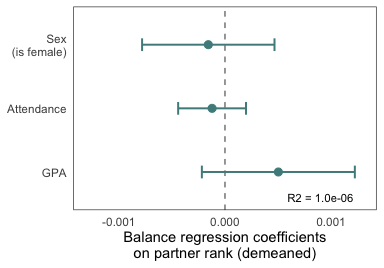

In [ ]:
balance_plot

All three coefficients are close to zero and their confidence intervals
include zero; the $R^2$ is about $10^{-6}$. Girls and boys, and children
with high or low attendance and grades, met partners of the same
expected rank.

In [ ]:
write_csv(balance_table, here("output", "tables", "figure1d_balance.csv"))
save_figure(balance_plot, "figure1d_balance", width = 3.6, height = 2.6)

# Session information

In [ ]:
sessionInfo()
## R version 4.3.2 (2023-10-31)
## Platform: aarch64-apple-darwin20 (64-bit)
## Running under: macOS 26.7.1
## 
## Matrix products: default
## BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
## LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0
## 
## locale:
## [1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8
## 
## time zone: America/Santiago
## tzcode source: internal
## 
## attached base packages:
## [1] stats     graphics  grDevices utils     datasets  methods   base     
## 
## other attached packages:
##  [1] lfe_3.1.1       Matrix_1.6-1.1  lubridate_1.9.4 forcats_1.0.0  
##  [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.4     readr_2.1.5    
##  [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0
## [13] here_1.0.1     
## 
## loaded via a namespace (and not attached):
##  [1] sandwich_3.1-1    generics_0.1.3    stringi_1.8.7     lattice_0.22-6   
##  [5] hms_1.1.3         digest_0.6.37     magrittr_2.0.3    evaluate_1.0.3   
##  [9] grid_4.3.2        timechange_0.3.0  fastmap_1.2.0     rprojroot_2.0.4  
## [13] jsonlite_2.0.0    Formula_1.2-5     scales_1.3.0      textshaping_1.0.0
## [17] cli_3.6.4         rlang_1.1.6       crayon_1.5.3      bit64_4.6.0-1    
## [21] munsell_0.5.1     withr_3.0.2       yaml_2.3.10       tools_4.3.2      
## [25] parallel_4.3.2    tzdb_0.5.0        colorspace_2.1-1  vctrs_0.6.5      
## [29] R6_2.6.1          zoo_1.8-13        lifecycle_1.0.4   bit_4.6.0        
## [33] vroom_1.6.5       ragg_1.3.3        pkgconfig_2.0.3   pillar_1.10.2    
## [37] gtable_0.3.6      glue_1.8.0        systemfonts_1.2.2 xfun_0.52        
## [41] tidyselect_1.2.1  knitr_1.50        farver_2.1.2      xtable_1.8-4     
## [45] htmltools_0.5.8.1 rmarkdown_2.29    compiler_4.3.2

[Continue to Figure 2: classroom
networks](04_figure2_classroom_networks.ipynb).